# RiskLens: Choosing the threshold

**Goal of this notebook:** my final model (without gender and age, calibrated) gives each applicant a probability of default. To actually use it I need a decision rule: flag an applicant when the probability is above some threshold. Here I choose that threshold and look at what it does.

**Why calibration matters here:** because the probabilities are real (notebook 08), I can work out the best threshold from costs instead of guessing. If a missed default costs `r` times as much as a false alarm, then flagging an applicant is worth it when `p × r > (1 − p) × 1`, which means when **p > 1 / (1 + r)**. This only works if the probabilities are calibrated, otherwise the formula gives the wrong threshold.

**An important assumption:** I don't know Home Credit's real costs, so `r` is my own assumption. I use **r = 5** as the base case and look at 2, 3, 10 and 20 to see how much it matters. A real lender would use its own numbers.

**What I'll do**
1. Load the final model and calibrator
2. Work out the thresholds from the formula
3. See what each threshold does on the test half
4. Draw the cost curve
5. Compare with flagging nobody and flagging everybody
6. Check the gender and age groups at the final threshold
7. Save the decision rule for the API

## 1. Loading the final model

In [2]:
# Step 1: Setup and sanity check

import json
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, confusion_matrix

df = pd.read_csv("../data/processed/train_merged.csv")
y = df["TARGET"]
X = df.drop(columns=["TARGET", "SK_ID_CURR"])
X = X.replace([np.inf, -np.inf], np.nan)

cat_cols = X.select_dtypes(exclude="number").columns
for c in cat_cols:
    X[c] = X[c].astype("category")

drop_cols = ["CODE_GENDER", "DAYS_BIRTH", "AGE"]

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
idx_cal, idx_test = train_test_split(
    np.arange(len(y_val)), test_size=0.5, stratify=y_val, random_state=42
)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

model = joblib.load("../models/lgbm_model_nosens.joblib")
platt = joblib.load("../models/platt_calibrator_nosens.joblib")

raw = model.predict_proba(X_val.drop(columns=drop_cols))[:, 1]
prob = platt.predict_proba(logit(raw).reshape(-1, 1))[:, 1]

p_test = prob[idx_test]
y_test = y_val.iloc[idx_test].values

# should be about 0.7647 and 0.0673, like in notebook 09
print(roc_auc_score(y_test, p_test), brier_score_loss(y_test, p_test))

0.764685673895233 0.06730705301549403


The AUC is **0.7647** and the Brier score is **0.0673**, the same as the "without gender and age" model in notebook 09, so the saved files are the right ones. As before, I only evaluate on the **test half (30,752 applicants)**, which the calibrator never saw.

## 2. The decision rule

In [3]:
# Step 2: The decision rule

for r in [2, 3, 5, 10, 20]:
    print("missed default costs", r, "x a false alarm -> flag if p >", round(1 / (1 + r), 3))

missed default costs 2 x a false alarm -> flag if p > 0.333
missed default costs 3 x a false alarm -> flag if p > 0.25
missed default costs 5 x a false alarm -> flag if p > 0.167
missed default costs 10 x a false alarm -> flag if p > 0.091
missed default costs 20 x a false alarm -> flag if p > 0.048


Flagging someone costs me a false alarm with probability (1 − p), and not flagging them costs me a missed default with probability p, which is `r` times worse. So I flag when the missed default is the bigger expected cost.

| A missed default costs... | Flag if probability is above |
|---|---|
| 2 times a false alarm | 33.3% |
| 3 times | 25.0% |
| 5 times (my base case) | 16.7% |
| 10 times | 9.1% |
| 20 times | 4.8% |

The more expensive a missed default is, the lower the threshold gets.

## 3. What each threshold does on the test half

In [4]:
# Step 3: What each threshold does on the test half

def at_threshold(p, y, t):
    flag = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, flag, labels=[0, 1]).ravel()
    return {
        "threshold": round(t, 3),
        "flagged": flag.mean(),
        "recall": tp / (tp + fn),
        "precision": tp / (tp + fp),
        "false positive rate": fp / (fp + tn),
        "missed defaults": fn,
        "false alarms": fp,
    }

rows = []
for r in [2, 3, 5, 10, 20]:
    row = at_threshold(p_test, y_test, 1 / (1 + r))
    row = {"r": r, **row}
    rows.append(row)

print(pd.DataFrame(rows).round(3))

    r  threshold  flagged  recall  precision  false positive rate  \
0   2      0.333    0.017   0.093      0.436                0.011   
1   3      0.250    0.048   0.213      0.360                0.033   
2   5      0.167    0.124   0.405      0.263                0.100   
3  10      0.091    0.296   0.656      0.179                0.264   
4  20      0.048    0.538   0.850      0.128                0.510   

   missed defaults  false alarms  
0             2253           298  
1             1953           944  
2             1477          2820  
3              853          7466  
4              373         14430  


The test half has about 2,483 defaults and 28,269 repayers.

| Cost ratio r | Threshold | Flagged | Recall | Precision | False positive rate | Missed defaults | False alarms |
|---|---|---|---|---|---|---|---|
| 2 | 33.3% | 1.7% | 9.3% | 43.6% | 1.1% | 2,253 | 298 |
| 3 | 25.0% | 4.8% | 21.3% | 36.0% | 3.3% | 1,953 | 944 |
| **5** | **16.7%** | **12.4%** | **40.5%** | **26.3%** | **10.0%** | **1,477** | **2,820** |
| 10 | 9.1% | 29.6% | 65.6% | 17.9% | 26.4% | 853 | 7,466 |
| 20 | 4.8% | 53.8% | 85.0% | 12.8% | 51.0% | 373 | 14,430 |

- A lower threshold catches more defaulters, but it flags many more people. At r = 10 the model catches 66% of the defaulters but flags almost a third of all applicants, and at r = 20 it flags more than half of them, which isn't really a useful filter anymore.
- At my base case (r = 5) it flags **12.4%** of the applicants, catches **40.5%** of the defaulters, and about 1 in 4 of the people flagged really defaults (26.3%). That's 1,477 missed defaults and 2,820 false alarms.
- Even at the best threshold the model misses more than half of the defaulters. It's decision support, not a crystal ball.

## 4. Cost curve

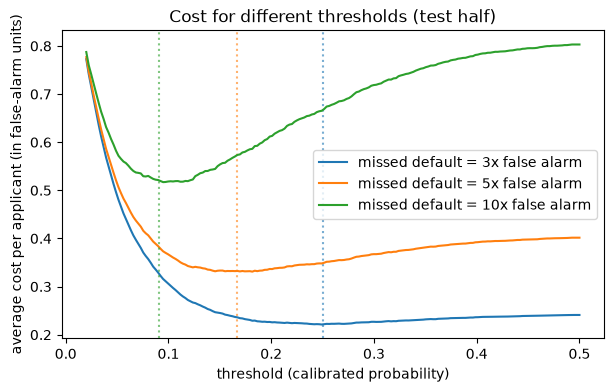

In [5]:
# Step 4: Cost curve (figure for the README)

ts = np.linspace(0.02, 0.5, 200)

plt.figure(figsize=(7, 4))
for r in [3, 5, 10]:
    costs = []
    for t in ts:
        flag = p_test >= t
        fn = ((~flag) & (y_test == 1)).sum()
        fp = (flag & (y_test == 0)).sum()
        costs.append((r * fn + fp) / len(y_test))
    line, = plt.plot(ts, costs, label=f"missed default = {r}x false alarm")
    plt.axvline(1 / (1 + r), linestyle=":", color=line.get_color(), alpha=0.6)

plt.xlabel("threshold (calibrated probability)")
plt.ylabel("average cost per applicant (in false-alarm units)")
plt.title("Cost for different thresholds (test half)")
plt.legend()
plt.savefig("../reports/figures/threshold_cost_curve.png", dpi=150, bbox_inches="tight")
plt.show()

For each threshold I counted the missed defaults and the false alarms on the test half and turned them into an average cost per applicant (in false-alarm units). The dotted lines are the thresholds from the formula.

- **The lowest point of each curve is right at its dotted line** (about 25% for r = 3, 16.7% for r = 5 and 9.1% for r = 10). So the formula and the real data agree. This is a nice extra check that the calibration worked, because with wrong probabilities the lowest points wouldn't line up like this.
- **The curves are fairly flat around the minimum.** For r = 5, anything from roughly 15% to 22% costs about the same, so the exact threshold isn't critical.
- **They are steep on the left.** A threshold that's too low flags far too many people and gets expensive quickly.
- The curves are a bit jagged because the test half is only 30,752 applicants.

## 5. Compared with flagging nobody or everybody

In [6]:
# Step 5: Compare with doing nothing

r = 5
t_final = 1 / (1 + r)

flag = p_test >= t_final
fn = ((~flag) & (y_test == 1)).sum()
fp = (flag & (y_test == 0)).sum()

cost_model = (r * fn + fp) / len(y_test)
cost_nobody = r * y_test.mean()      # flag nobody: every default is missed
cost_everybody = 1 - y_test.mean()   # flag everybody: every good customer is a false alarm

print("threshold:", round(t_final, 3))
print("cost with the model:", round(cost_model, 3))
print("cost flagging nobody:", round(cost_nobody, 3))
print("cost flagging everybody:", round(cost_everybody, 3))
print("saving vs flagging nobody:", round(1 - cost_model / cost_nobody, 3))

threshold: 0.167
cost with the model: 0.332
cost flagging nobody: 0.404
cost flagging everybody: 0.919
saving vs flagging nobody: 0.178


Average cost per applicant with r = 5 (in false-alarm units):

| Strategy | Cost |
|---|---|
| Use the model (threshold 16.7%) | 0.332 |
| Flag nobody (every default is missed) | 0.404 |
| Flag everybody (every repayer is a false alarm) | 0.919 |

The model is **17.8% cheaper than flagging nobody**, and much cheaper than flagging everybody. So it does help, but the improvement is moderate, which fits an AUC of about 0.76. And this number depends on my assumption of r = 5: it would be smaller if a missed default were cheaper, and bigger if it were more expensive.

In [7]:
# to see the saving for other cost assumptions

for r_ in [3, 5, 10]:
    t = 1 / (1 + r_)
    flag = p_test >= t
    fn_ = ((~flag) & (y_test == 1)).sum()
    fp_ = (flag & (y_test == 0)).sum()
    cost = (r_ * fn_ + fp_) / len(y_test)
    nobody = r_ * y_test.mean()
    print(r_, "| model:", round(cost, 3), "| nobody:", round(nobody, 3), "| saving:", round(1 - cost / nobody, 3))

3 | model: 0.221 | nobody: 0.242 | saving: 0.087
5 | model: 0.332 | nobody: 0.404 | saving: 0.178
10 | model: 0.52 | nobody: 0.807 | saving: 0.356


## 6. The groups at the final threshold

The final model doesn't use gender and age, but I use these columns to check the results. This is the same check as in notebook 09, now at the cost-based threshold (16.7%) instead of the top 20%.

In [8]:
# Step 6: Check the groups at this threshold

X_test = X_val.iloc[idx_test]
groups = pd.DataFrame({
    "gender": X_test["CODE_GENDER"].astype(str).values,
    "age_group": pd.cut(-X_test["DAYS_BIRTH"] / 365, bins=[20, 30, 40, 50, 60, 70]).astype(str).values,
    "y": y_test,
    "flag": (p_test >= t_final).astype(int),
})

def group_check(col):
    rows = []
    for name, g in groups.groupby(col):
        tn, fp, fn, tp = confusion_matrix(g["y"], g["flag"], labels=[0, 1]).ravel()
        rows.append({
            col: name, "n": len(g),
            "real default rate": g["y"].mean(),
            "flagged": g["flag"].mean(),
            "recall": tp / (tp + fn),
            "false positive rate": fp / (fp + tn),
        })
    return pd.DataFrame(rows).round(3)

print(group_check("gender"))
print(group_check("age_group"))

  gender      n  real default rate  flagged  recall  false positive rate
0      F  20345              0.070    0.103   0.368                0.083
1      M  10407              0.102    0.167   0.455                0.134
  age_group     n  real default rate  flagged  recall  false positive rate
0  (20, 30]  4366              0.113    0.261   0.528                0.227
1  (30, 40]  8250              0.098    0.153   0.459                0.119
2  (40, 50]  7662              0.075    0.106   0.382                0.084
3  (50, 60]  6807              0.066    0.073   0.298                0.058
4  (60, 70]  3667              0.044    0.031   0.138                0.026


| Gender | n | Real default rate | Flagged | Recall | False positive rate |
|---|---|---|---|---|---|
| Women | 20,345 | 7.0% | 10.3% | 36.8% | 8.3% |
| Men | 10,407 | 10.2% | 16.7% | 45.5% | 13.4% |

| Age group | n | Real default rate | Flagged | Recall | False positive rate |
|---|---|---|---|---|---|
| 20-30 | 4,366 | 11.3% | 26.1% | 52.8% | 22.7% |
| 30-40 | 8,250 | 9.8% | 15.3% | 45.9% | 11.9% |
| 40-50 | 7,662 | 7.5% | 10.6% | 38.2% | 8.4% |
| 50-60 | 6,807 | 6.6% | 7.3% | 29.8% | 5.8% |
| 60-70 | 3,667 | 4.4% | 3.1% | 13.8% | 2.6% |

- **Gender:** men are flagged about 1.6 times as often as women (16.7% vs 10.3%), and the false positive rate is 13.4% for men against 8.3% for women. The real default rates differ by about 1.5 times, so this is close to what the data says.
- **Age:** applicants aged 20-30 are flagged **8.4 times** as often as those aged 60-70 (26.1% vs 3.1%), and the false positive rate is 22.7% against 2.6%. The real default rates only differ by 2.6 times, so the flagging gap is much bigger than the risk gap. A young applicant who would have repaid is a lot more likely to be flagged by mistake.
- **Compared with notebook 09** (flagging the top 20%): the ratios are bigger now (for age, 5.3 times then and 8.4 times now), but the gaps in percentage points are smaller (the false positive rate gap between the youngest and oldest group went from 28 points to 20). A higher cutoff only picks out the extreme cases, which exaggerates the ratios.
- **The oldest group is tiny in this table:** only 3.1% of them are flagged and the recall is 13.8%. There are only about 160 defaulters in that group, so about 20 of them are caught, and I wouldn't read too much into it.
- This is the part of the project I'm least comfortable with. The model doesn't use gender or age, but the gaps are still there, because of other columns and because the groups really do differ. That's why I recommend using the flags for manual review and not for automatic rejection (see the model card).

## 7. Saving the decision rule

I saved the threshold (0.1667), the assumed cost ratio, the columns to drop and the file names in `models/config.json`. The API will read this file, so the threshold isn't hardcoded in the code. The `models/` folder is in `.gitignore`, so it stays on my computer.

In [9]:
# Step 7: Save the decision rule for the API

config = {
    "threshold": round(float(t_final), 4),
    "assumed_cost_ratio": r,
    "dropped_columns": drop_cols,
    "model_file": "lgbm_model_nosens.joblib",
    "calibrator_file": "platt_calibrator_nosens.joblib",
}
with open("../models/config.json", "w") as f:
    json.dump(config, f, indent=2)
print(config)

{'threshold': 0.1667, 'assumed_cost_ratio': 5, 'dropped_columns': ['CODE_GENDER', 'DAYS_BIRTH', 'AGE'], 'model_file': 'lgbm_model_nosens.joblib', 'calibrator_file': 'platt_calibrator_nosens.joblib'}


## Summary

**What I did**
- Used the cost formula p > 1 / (1 + r) to turn the calibrated probabilities into a decision rule
- Chose r = 5 (a missed default costs 5 times a false alarm) as the base case, which gives a threshold of **16.7%**
- Checked the result on the test half, with a cost curve and at group level

**Results (test half, threshold 16.7%)**
- Flags 12.4% of the applicants, catches 40.5% of the defaulters, precision 26.3%
- Cost per applicant 0.332, which is 17.8% lower than flagging nobody (0.404)
- The lowest points of the cost curves match the formula, which supports the calibration

**Limits**
- r = 5 is my assumption, not a real cost
- The model still misses more than half of the defaulters at this threshold
- Large gaps in who gets flagged, especially by age, even without using age
- One random split, no confidence intervals

**Next:** put the final code into `src/`, build the API, Docker, drift check